# Food Access Visualizations — USDA 2019 LRAM (Cook County, IL)

This notebook makes the figures for the analysis. It reads the scored file from the pipeline (`outputs/cook_county_scored.csv`) and builds one chart at a time. For each figure we added a plain explanation of what it measures and how to read it, plus which research question, hypothesis, or acceptance criterion it supports.

**Data note:** the LRAM data is historical — 2010 tract boundaries and population, 2014-18 ACS figures, and 2019 retailer locations. These charts describe *areas* (census tracts), not individual people, and they are not a 2026 snapshot.

In [ ]:
# Import the libraries used throughout the notebook.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

In [ ]:
# Path to the scored data created by the pipeline.
# CHANGE THIS PATH IF YOUR FILE IS STORED SOMEWHERE ELSE.
SCORED_PATH = Path("outputs/cook_county_scored.csv")

# CHANGE THESE TWO LINES IF YOUR DATA IS FOR ANOTHER AREA.
STATE_NAME  = "Illinois"
COUNTY_NAME = "Cook County"

# Combine the county and state names into one label for chart titles.
AREA_LABEL = f"{COUNTY_NAME}, {STATE_NAME}"

# Create a folder for saving the finished charts (created automatically if missing).
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

# The six indicators used to calculate the food-access priority score.
INDEX_VARS = [
    "PovertyRate",       # % population below the federal poverty line
    "lapop1share",       # % of tract >1 mi from a supermarket
    "lalowi1share",      # % low-income AND >1 mi from a supermarket
    "lahunv1share",      # % housing units with no vehicle AND >1 mi
    "lasnap1share",      # % SNAP households AND >1 mi
    "MedianFamilyIncome" # inverted in scoring: lower income = higher need
]

# Shorter, easier-to-read names for the charts.
LABELS = {
    "PovertyRate":        "Poverty Rate (%)",
    "lapop1share":        "% Population >1 mi from Supermarket",
    "lalowi1share":       "% Low-Income & >1 mi",
    "lahunv1share":       "% No-Vehicle & >1 mi",
    "lasnap1share":       "% SNAP & >1 mi",
    "MedianFamilyIncome": "Median Family Income ($)",
    "PriorityScore":      "Priority Score (0-1)",
}

# Load the scored CSV into a DataFrame.
df = pd.read_csv(SCORED_PATH)

# Format census tract IDs as 11-digit strings for consistent labeling.
df["CensusTract"] = df["CensusTract"].astype(str).str.split(".").str[0].str.zfill(11)

# Confirm what was loaded.
print(f"Loaded {len(df):,} tracts, {df.shape[1]} columns from {SCORED_PATH}")
print("PriorityScore range:", round(df.PriorityScore.min(), 3), "->", round(df.PriorityScore.max(), 3))

Loaded 1,314 tracts, 21 columns from outputs\cook_county_scored.csv
PriorityScore range: 0.003 -> 0.967


## Figure 1 — Distribution of the six indicators

**What this is measuring:** How the values are spread out for each of the six indicators that go into the score (poverty, the four distance-share measures, and income).

**How to read it:** Each small chart is one indicator. The horizontal axis is the value, the height of each bar is how many tracts fall in that range. Tall bars on the left mean most tracts have low values, while a long tail to the right means a few tracts have very high values.

**What it answers:** A supporting figure for the cleaning and scaling step. It shows why we rescale everything before scoring (income runs into the tens of thousands while the other measures sit on a 0-100 scale).

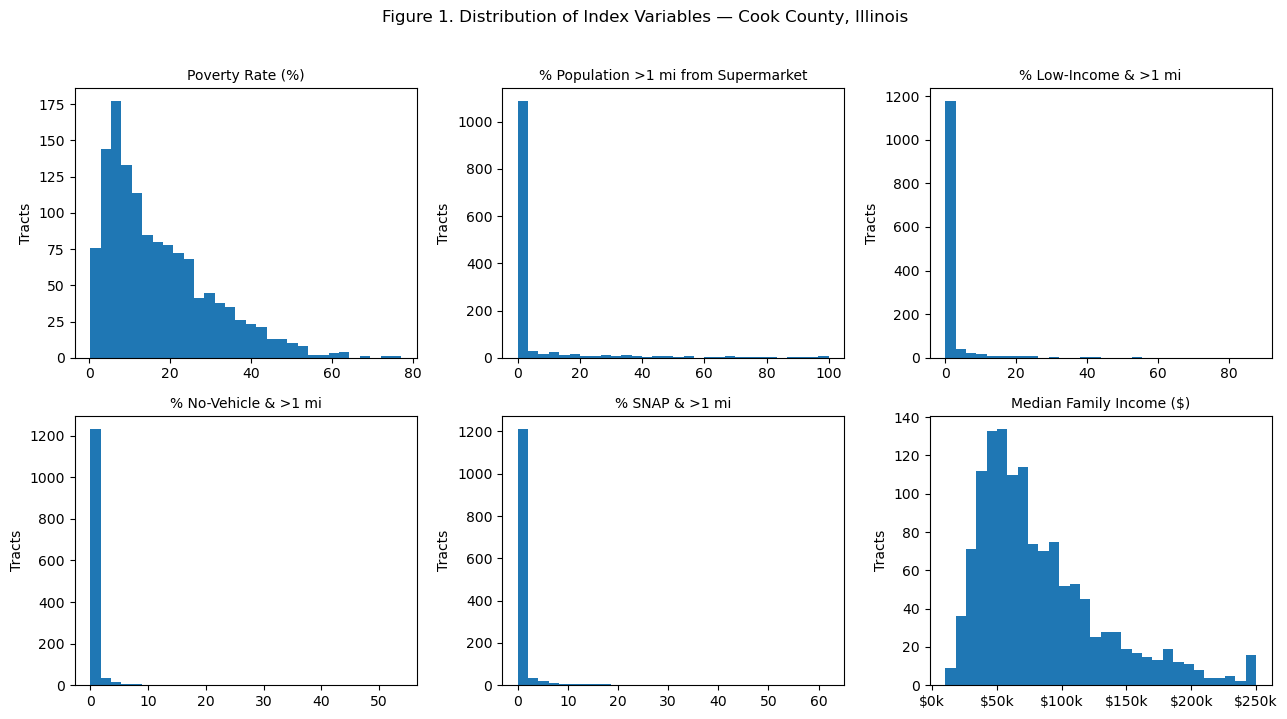

Summary (median / min / max):
  Poverty Rate (%)                                 13.5        0.3       77.1
  % Population >1 mi from Supermarket               0.0        0.0      100.0
  % Low-Income & >1 mi                              0.0        0.0       87.7
  % No-Vehicle & >1 mi                              0.0        0.0       53.9
  % SNAP & >1 mi                                    0.0        0.0       62.0
  Median Family Income ($)                      69436.0    10131.0   250001.0


In [ ]:
# Create six small plots arranged in two rows and three columns.
fig, axes = plt.subplots(2, 3, figsize=(13, 7))

# Draw a histogram for each indicator to show how its values are distributed.
for ax, v in zip(axes.ravel(), INDEX_VARS):
    data = df[v].dropna()
    ax.hist(data, bins=30)
    ax.set_title(LABELS.get(v, v), fontsize=10)
    ax.set_ylabel("Tracts")
    # Show income in thousands of dollars so the axis is easy to read.
    if v == "MedianFamilyIncome":
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1000:.0f}k"))

# Add an overall title, tidy the spacing, save, and display.
fig.suptitle(f"Figure 1. Distribution of Index Variables — {AREA_LABEL}", fontsize=12, y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig1_distributions.png", bbox_inches="tight")
plt.show()

# Print a short numeric summary so the finding does not depend on reading the chart.
print("Summary (median / min / max):")
for v in INDEX_VARS:
    s = df[v]
    print(f"  {LABELS.get(v, v):42s} {s.median():10.1f} {s.min():10.1f} {s.max():10.1f}")

## Figure 2 — How many tracts actually have a distance-share value

**What this is measuring:** For each of the four distance-share measures, how many tracts have a real value above zero versus how many are zero.

**How to read it:** Each bar is one measure, split into two parts. The lower part is tracts with a value above zero and the upper part is tracts sitting at zero.

**What it answers:** A supporting figure for the cleaning step. About 77% of tracts are zero because they are not low-access at one mile. That zero is a real value, not missing data. We added this so the big stack of zeros in Figure 1 is clearly explained and not mistaken for an error.

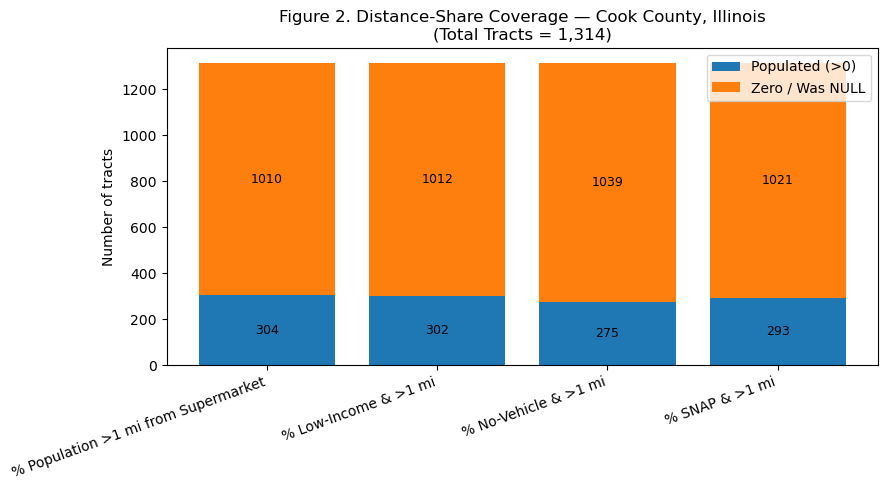

Example: lapop1share populated in 304 of 1314 tracts (23%); 1010 are zero/NULL (77%).


In [ ]:
# The four share variables that measure distance from supermarkets.
share_vars = ["lapop1share", "lalowi1share", "lahunv1share", "lasnap1share"]

# Count tracts with a real value (>0) and tracts set to 0 (were NULL) for each.
populated = [(df[v] > 0).sum() for v in share_vars]
zerofill  = [(df[v] == 0).sum() for v in share_vars]

# Positions for the four bars.
x = np.arange(len(share_vars))

# Stacked bars: populated on the bottom, zero/NULL on top. Two groups need two colors.
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x, populated, label="Populated (>0)")
ax.bar(x, zerofill, bottom=populated, label="Zero / Was NULL")

# Label the axis, title, and legend.
ax.set_xticks(x); ax.set_xticklabels([LABELS[v] for v in share_vars], rotation=20, ha="right")
ax.set_ylabel("Number of tracts")
ax.set_title(f"Figure 2. Distance-Share Coverage — {AREA_LABEL}\n(Total Tracts = {len(df):,})")
ax.legend()

# Write the counts inside each bar section.
for i, (p, z) in enumerate(zip(populated, zerofill)):
    ax.text(i, p/2, str(p), ha="center", va="center", fontsize=9)
    ax.text(i, p + z/2, str(z), ha="center", va="center", fontsize=9)

fig.tight_layout()
fig.savefig(FIG_DIR / "fig2_share_coverage.png", bbox_inches="tight")
plt.show()

# Print one example in words.
print(f"Example: lapop1share populated in {populated[0]} of {len(df)} tracts "
      f"({populated[0]/len(df)*100:.0f}%); {zerofill[0]} are zero/NULL "
      f"({zerofill[0]/len(df)*100:.0f}%).")

## Figure 3 — Top-20 priority tracts

**What this is measuring:** The twenty tracts with the highest priority scores. The areas our tool flags as most in need of a closer look.

**How to read it:** Each bar is one tract, labeled by its census-tract code. Longer bar = higher priority score. The highest-priority tract is at the top.

**What it answers:** Question 3 (can a non-technical reader pick out the priority areas) and Acceptance Criterion 2 (a clean ranked output).

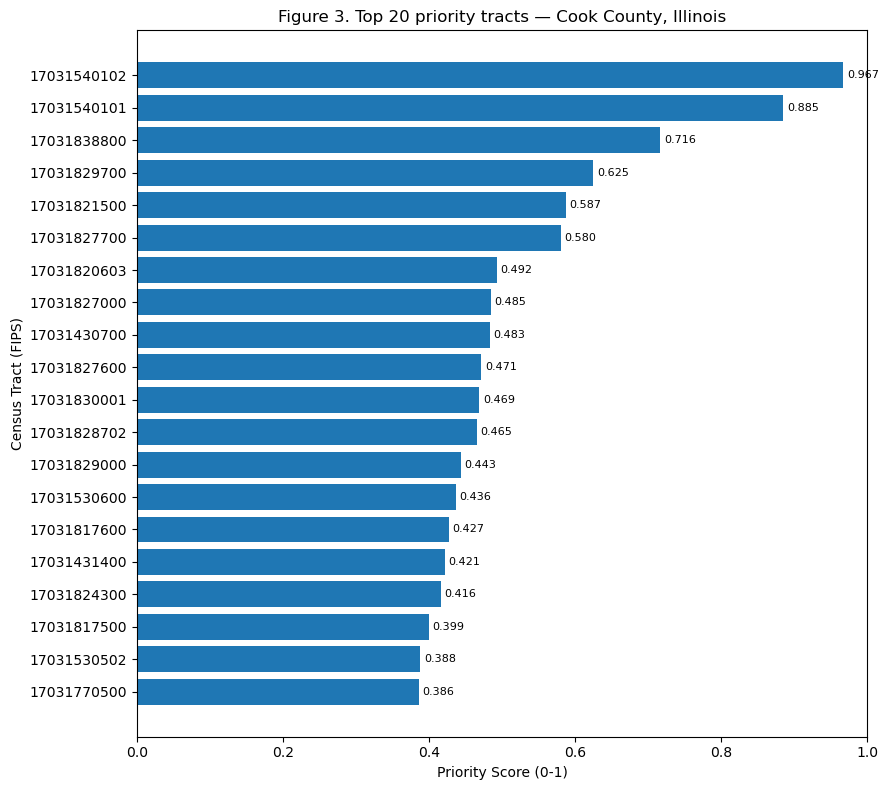

Highest-priority tract: 17031540102 | score 0.967


In [ ]:
# Sort by priority score and take the top 20 tracts.
top20 = df.sort_values("PriorityScore", ascending=False).head(20)

# Horizontal bar chart, highest-priority tract at the top.
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top20["CensusTract"], top20["PriorityScore"])
ax.invert_yaxis()

# Axis labels and title.
ax.set_xlabel(LABELS["PriorityScore"])
ax.set_ylabel("Census Tract (FIPS)")
ax.set_title(f"Figure 3. Top 20 Priority Tracts — {AREA_LABEL}")

# Print each score at the end of its bar.
for y, score in enumerate(top20["PriorityScore"]):
    ax.text(score + 0.005, y, f"{score:.3f}", va="center", fontsize=8)

# Leave a little room on the right for the score labels.
ax.set_xlim(0, min(1.0, top20["PriorityScore"].max() + 0.08))
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3_top20.png", bbox_inches="tight")
plt.show()

# Name the single highest-priority tract.
print("Highest-priority tract:", top20.iloc[0]["CensusTract"],
      "| score", round(top20.iloc[0]["PriorityScore"], 3))

## Figure 4 — Priority score vs. the USDA's own food-access flag

**What this is measuring:** Whether our score agrees with the USDA's existing yes/no label called LILA (low-income and low-access). It compares the priority scores of the tracts USDA flagged against the tracts it did not.

**How to read it:** Each box covers the middle range of scores for that group, and the line inside is the typical (median) tract. The higher the box, the higher the scores in that group. A higher box for the LILA group means those tracts score higher on our tool too.

**What it answers:** Acceptance Criterion 2 — it checks our score against the USDA's official measure. If the flagged tracts score higher, it shows our score agrees with the USDA while still giving a finer ranking within each group.

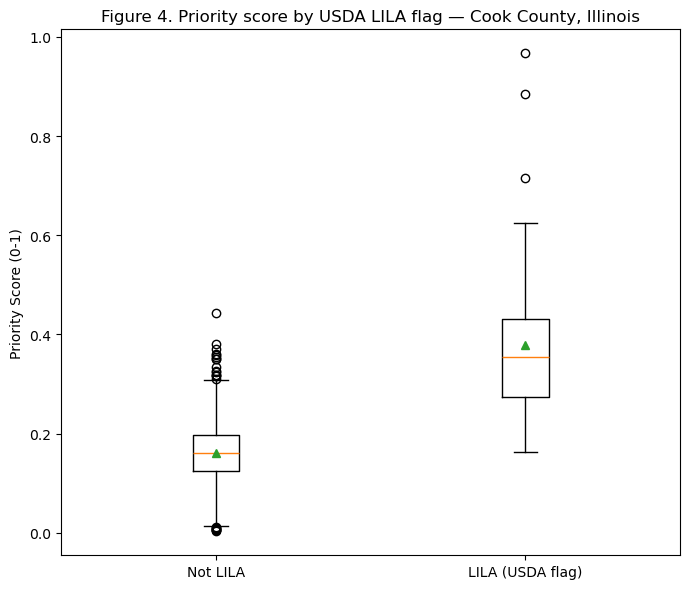

Median priority score — LILA: 0.354 vs non-LILA: 0.161 (LILA tracts: 51)


In [ ]:
# This figure needs the USDA LILA flag, which the pipeline now exports.
if "LILATracts_1And10" in df.columns:
    # Split priority scores into the two groups: LILA-flagged vs not.
    groups = [df[df["LILATracts_1And10"] != 1]["PriorityScore"],
              df[df["LILATracts_1And10"] == 1]["PriorityScore"]]

    # Simple side-by-side boxplot comparison.
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.boxplot(groups, tick_labels=["Not LILA", "LILA (USDA flag)"], showmeans=True)
    ax.set_ylabel(LABELS["PriorityScore"])
    ax.set_title(f"Figure 4. Priority Score by USDA LILA Flag — {AREA_LABEL}")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "fig4_lila_boxplot.png", bbox_inches="tight")
    plt.show()

    # Print the group medians so the comparison is clear in text.
    print(f"Median priority score — LILA: {groups[1].median():.3f} "
          f"vs non-LILA: {groups[0].median():.3f} "
          f"(LILA tracts: {int((df['LILATracts_1And10']==1).sum())})")
else:
    print("LILATracts_1And10 not in file — re-run the pipeline so it is included in the export.")

## Figure 5 — What drives each top tract's score

**What this is measuring:** For each of the top tracts, how much each of the six indicators contributed to its score. We can see *why* a tract ranks high.

**How to read it:** Each row is a tract, and each colored segment is one indicator's contribution. A longer segment means that indicator pushed the tract's score up more. The full bar length is the sum of the six parts, while the final score is their average. Read the segments
as "which factors mattered," not as the score itself.

**What it answers:** The "explain why a tract was chosen" part of Question 3. It makes the score transparent instead of a single number.

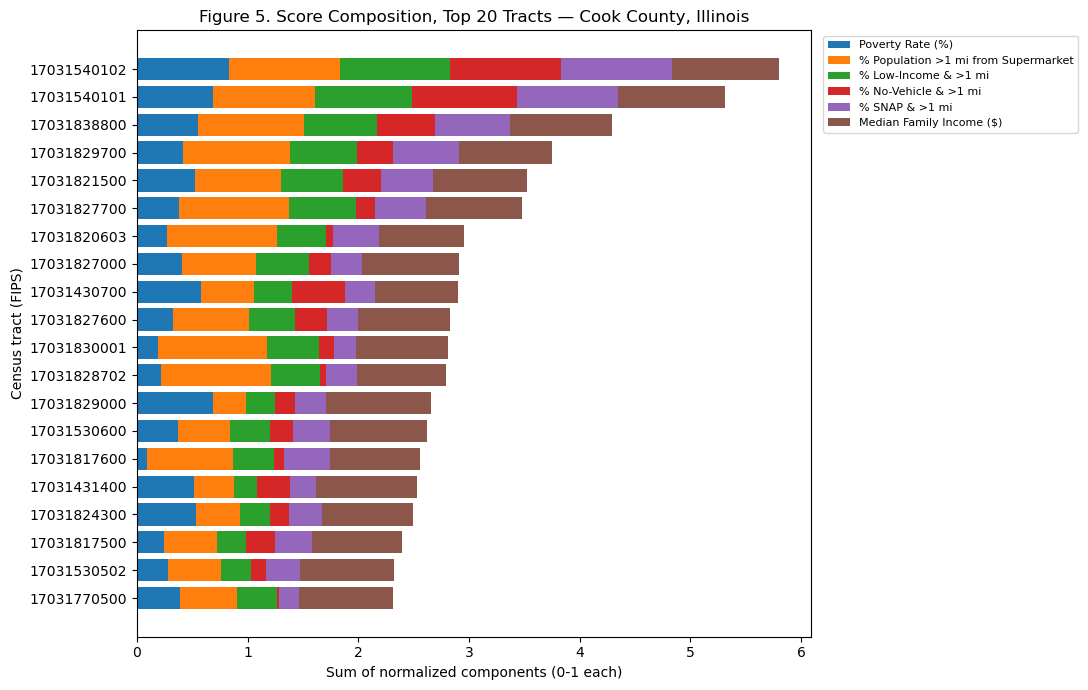

Note: bar length = sum of the six normalized parts; the final PriorityScore is their average.


In [ ]:
# Column names for the six normalized components produced by the pipeline.
norm_cols = [v + "_score" for v in INDEX_VARS]

# If the _score columns aren't in the file (e.g. an older export), recompute them
# with the same min-max logic the pipeline uses, so this figure still works.
if not all(c in df.columns for c in norm_cols):
    def _minmax(s):
        lo, hi = s.min(), s.max()
        return (s - lo) / (hi - lo) if hi > lo else pd.Series(0.0, index=s.index)
    for v in INDEX_VARS:
        n = _minmax(df[v])
        if v == "MedianFamilyIncome":   # invert so higher = more need
            n = 1 - n
        df[v + "_score"] = n

# Pull their normalized components and label them with the readable variable names.
comp = top20[norm_cols].copy()
comp.columns = INDEX_VARS

# Stacked horizontal bars: one segment per component. Six categories need distinct colors,
# so color here encodes information (which indicator) rather than decoration.
fig, ax = plt.subplots(figsize=(11, 7))
bottom = np.zeros(len(top20))
for v in INDEX_VARS:
    ax.barh(top20["CensusTract"], comp[v].values, left=bottom, label=LABELS.get(v, v))
    bottom += comp[v].values

ax.invert_yaxis()
ax.set_xlabel("Sum of normalized components (0-1 each)")
ax.set_ylabel("Census tract (FIPS)")
ax.set_title(f"Figure 5. Score Composition, Top 20 Tracts — {AREA_LABEL}")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig5_composition.png", bbox_inches="tight")
plt.show()

print("Note: bar length = sum of the six normalized parts; the final PriorityScore is their average.")

## Figure 6 — Priority score vs. each individual indicator

**What this is measuring:** How closely each individual hardship indicator moves together with the final priority score.

**How to read it:** Each bar is one indicator. The longer the bar, the more that indicator and the priority score rise and fall together (on a 0-to-1 scale). The dashed line marks 0.50, the target we set for a "strong" relationship.

**What it answers:** Hypothesis 3 — that the overall score reflects each individual food-access barrier. All five indicators clear the 0.50 line (they range from about 0.58 to 0.73), so the score is genuinely reflecting all of them, not just one.

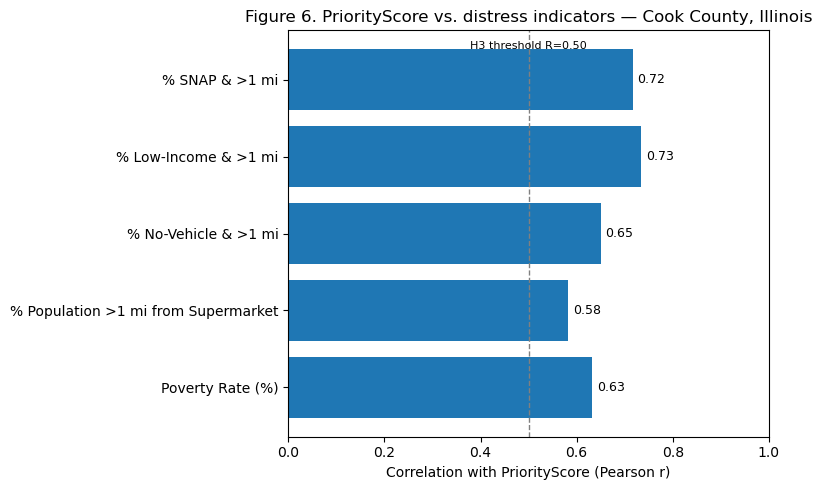

Correlation of PriorityScore with each distress indicator (Hypothesis 3, want R>=0.50):
  lasnap1share     r = +0.716  OK
  lalowi1share     r = +0.734  OK
  lahunv1share     r = +0.650  OK
  lapop1share      r = +0.582  OK
  PovertyRate      r = +0.632  OK


In [ ]:
# Correlate PriorityScore with each distress indicator (Hypothesis 3).
distress = ["lasnap1share", "lalowi1share", "lahunv1share", "lapop1share", "PovertyRate"]
corrs = [np.corrcoef(df["PriorityScore"], df[v])[0, 1] for v in distress]

# Horizontal bar chart of the correlations.
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([LABELS.get(v, v) for v in distress], corrs)
ax.invert_yaxis()
ax.set_xlabel("Correlation with PriorityScore (Pearson r)")
ax.set_xlim(0, 1)

# Mark the R >= 0.50 hypothesis threshold.
ax.axvline(0.50, linestyle="--", linewidth=1, color="grey")
ax.text(0.50, -0.4, "H3 threshold R=0.50", fontsize=8, ha="center")

# Label each bar with its value.
for y, r in enumerate(corrs):
    ax.text(r + 0.01, y, f"{r:.2f}", va="center", fontsize=9)

ax.set_title(f"Figure 6. PriorityScore vs. Distress Indicators — {AREA_LABEL}")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig6_h3_correlations.png", bbox_inches="tight")
plt.show()

# Print the values; all should clear 0.50 for Hypothesis 3 to hold.
print("Correlation of PriorityScore with each distress indicator (Hypothesis 3, want R>=0.50):")
for v, r in zip(distress, corrs):
    print(f"  {v:16s} r = {r:+.3f}  {'OK' if r >= 0.50 else 'below 0.50'}")

## Figure 7 — Low-access share by vehicle access in high-poverty tracts

**What this is measuring:** Among the high-poverty tracts only, whether the ones where people also lack cars have a higher share of low-income residents living far from a store than the ones with better car access.

**How to read it:** Tracts with better vehicle access on the left, worse vehicle access on the right. Each box covers the middle range for that group; the line inside is the typical tract. If the right box sits higher, worse vehicle access goes with a higher low-access share. A statistical test (a t-test) behind it confirms whether the gap is real or just chance.

**What it answers:** Question 1 and Hypothesis 1. The result is strong (the worse-vehicle group sits about 14 points higher) so among poor neighborhoods, lacking a car (not just being poor) is linked to being stranded far from a grocery store.

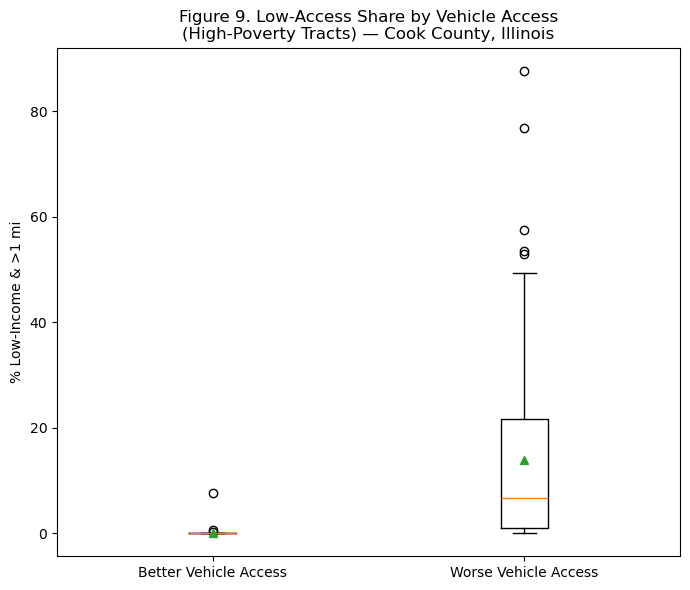

High-poverty tracts (PovertyRate > 13.5): n=657
  Worse vehicle access  mean lalowi1share = 13.91 (n=94)
  Better vehicle access mean lalowi1share = 0.01 (n=563)
  Difference = 13.90 points | Welch t = 7.71, p = 1.36e-11
  Criterion (>=10 pts and p<0.05): MET


In [ ]:
# Question 1 / Hypothesis 1: compare lalowi1share by vehicle access within high-poverty tracts.
# Define "high poverty" as above the county median poverty rate.
pov_median = df["PovertyRate"].median()
high_pov = df[df["PovertyRate"] > pov_median].copy()

# Within high-poverty tracts, split by median no-vehicle share.
hunv_median = high_pov["lahunv1share"].median()
low_veh  = high_pov[high_pov["lahunv1share"] >  hunv_median]["lalowi1share"]  # worse vehicle access
high_veh = high_pov[high_pov["lahunv1share"] <= hunv_median]["lalowi1share"]  # better vehicle access

# Welch two-sample t-test (unequal variances). Prefer scipy; fall back to a manual computation.
def welch_ttest(a, b):
    a, b = a.dropna(), b.dropna()
    try:
        from scipy import stats
        t, p = stats.ttest_ind(a, b, equal_var=False)
        return t, p
    except Exception:
        import math
        va, vb, na, nb = a.var(ddof=1), b.var(ddof=1), len(a), len(b)
        t = (a.mean() - b.mean()) / math.sqrt(va/na + vb/nb)
        p = 2 * (1 - 0.5 * (1 + math.erf(abs(t) / math.sqrt(2))))  # normal approx
        return t, p

t_stat, p_val = welch_ttest(low_veh, high_veh)

# Grouped boxplot comparing the two groups.
fig, ax = plt.subplots(figsize=(7, 6))
ax.boxplot([high_veh.dropna(), low_veh.dropna()],
           tick_labels=["Better Vehicle Access", "Worse Vehicle Access"], showmeans=True)
ax.set_ylabel(LABELS["lalowi1share"])
ax.set_title(f"Figure 9. Low-Access Share by Vehicle Access\n(High-Poverty Tracts) — {AREA_LABEL}")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig7_q1_vehicle_boxplot.png", bbox_inches="tight")
plt.show()

# Report the group means, the difference, and the test result in words.
diff = low_veh.mean() - high_veh.mean()
print(f"High-poverty tracts (PovertyRate > {pov_median:.1f}): n={len(high_pov)}")
print(f"  Worse vehicle access  mean lalowi1share = {low_veh.mean():.2f} (n={low_veh.notna().sum()})")
print(f"  Better vehicle access mean lalowi1share = {high_veh.mean():.2f} (n={high_veh.notna().sum()})")
print(f"  Difference = {diff:.2f} points | Welch t = {t_stat:.2f}, p = {p_val:.2e}")
print(f"  Criterion (>=10 pts and p<0.05): "
      f"{'MET' if (diff >= 10 and p_val < 0.05) else 'NOT met'}")

## Figure 8 *(optional)* — Map of priority score across the county

**What this is measuring:** The priority score shown on a real map of the county so we can see where the high-priority tracts are.

**How to read it:** Each small area is a census tract, shaded by its priority score (darker means higher priority). Clusters of dark areas show neighborhoods that stand out together.

**What it answers:** A supporting view for Question 3 (it makes the priorities easy to see at a glance). It needs a separate census-tract boundary file, so it stays optional and the notebook runs fine without it.

**To turn it on:** download the Illinois tract boundaries (TIGER/Line `cb_2019_17_tract_500k`), install geopandas, set `GEO_PATH` to that file, and run the cell.

C:\Users\amand\anaconda3\Lib\site-packages\pyogrio\core.py:35: RuntimeWarning: Could not detect GDAL data files.  Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


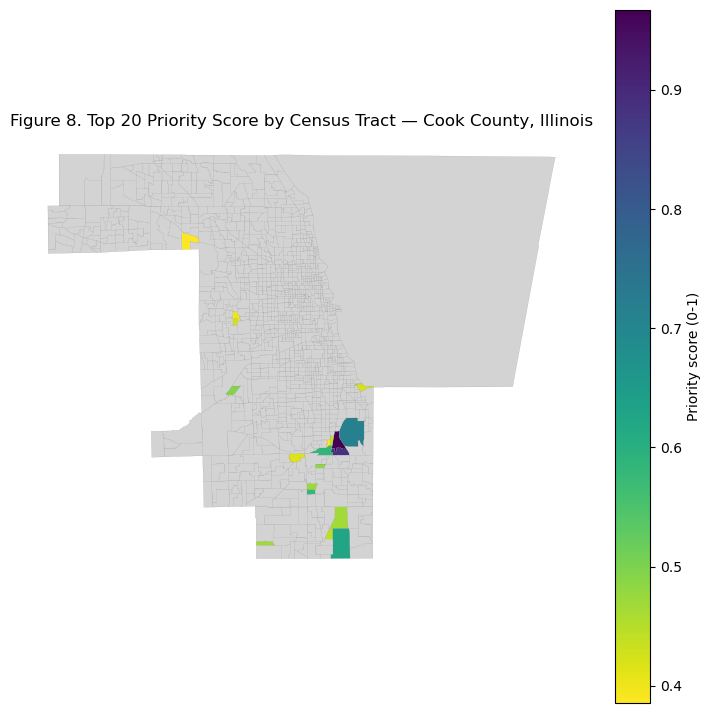

Mapped 20 tracts.


In [ ]:
# Optional map — requires a boundary file and geopandas.
GEO_PATH = "tl_2026_17_tract/tl_2026_17_tract.shp"  # e.g. "shapefiles/cb_2019_17_tract_500k.shp"  (Illinois tracts)

if GEO_PATH:
    try:
        import geopandas as gpd
        gdf = gpd.read_file(GEO_PATH)
        # Keep Cook County tracts (state 17 + county 031 -> prefix "17031").
        gdf = gdf[gdf["GEOID"].str.startswith("17031")]
        merged = gdf.merge(top20[["CensusTract", "PriorityScore"]],
                           left_on="GEOID", right_on="CensusTract", how="left")
        fig, ax = plt.subplots(figsize=(9, 9))
        merged.plot(column="PriorityScore", cmap="viridis_r", linewidth=0.1,
                    edgecolor="grey", legend=True, ax=ax,
                    legend_kwds={"label": "Priority score (0-1)"},
                    missing_kwds={"color": "lightgrey", "label": "No data"})
        ax.set_title(f"Figure 8. Top 20 Priority Score by Census Tract — {AREA_LABEL}")
        ax.axis("off")
        fig.savefig(FIG_DIR / "fig8_choropleth.png", bbox_inches="tight", dpi=150)
        plt.show()
        print(f"Mapped {merged['PriorityScore'].notna().sum()} tracts.")
    except ImportError:
        print("geopandas not installed. Run: pip install geopandas, then re-run this cell.")
    except Exception as e:
        print(f"Could not build the map: {e}")
else:
    print("Choropleth skipped — set GEO_PATH to a Cook County tract boundary file to enable it.")

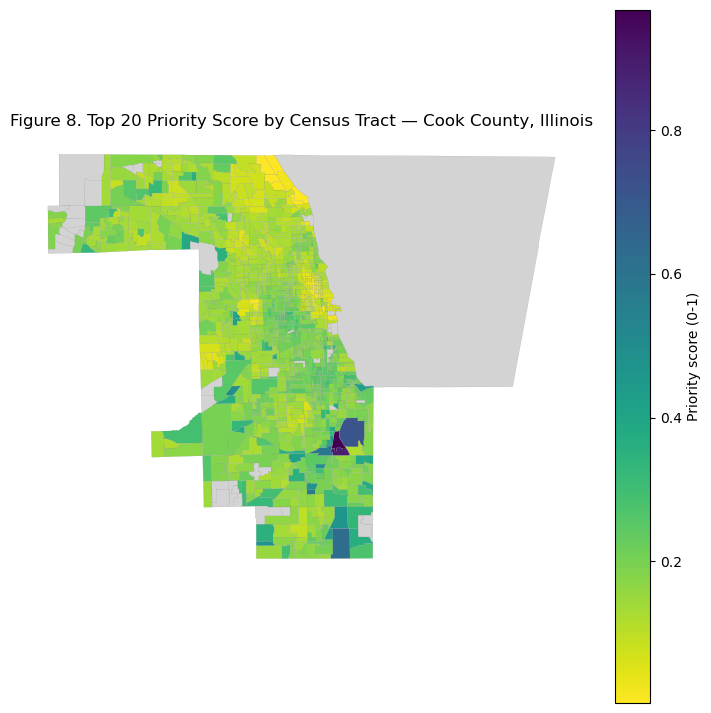

Mapped 1284 tracts.


In [ ]:
# Optional map — requires a boundary file and geopandas.
GEO_PATH = "tl_2026_17_tract/tl_2026_17_tract.shp"  # e.g. "shapefiles/cb_2019_17_tract_500k.shp"  (Illinois tracts)

if GEO_PATH:
    try:
        import geopandas as gpd
        gdf = gpd.read_file(GEO_PATH)
        # Keep Cook County tracts (state 17 + county 031 -> prefix "17031").
        gdf = gdf[gdf["GEOID"].str.startswith("17031")]
        merged = gdf.merge(df[["CensusTract", "PriorityScore"]],
                           left_on="GEOID", right_on="CensusTract", how="left")
        fig, ax = plt.subplots(figsize=(9, 9))
        merged.plot(column="PriorityScore", cmap="viridis_r", linewidth=0.1,
                    edgecolor="grey", legend=True, ax=ax,
                    legend_kwds={"label": "Priority score (0-1)"},
                    missing_kwds={"color": "lightgrey", "label": "No data"})
        ax.set_title(f"Figure 8. Top 20 Priority Score by Census Tract — {AREA_LABEL}")
        ax.axis("off")
        fig.savefig(FIG_DIR / "fig8_choropleth.png", bbox_inches="tight", dpi=150)
        plt.show()
        print(f"Mapped {merged['PriorityScore'].notna().sum()} tracts.")
    except ImportError:
        print("geopandas not installed. Run: pip install geopandas, then re-run this cell.")
    except Exception as e:
        print(f"Could not build the map: {e}")
else:
    print("Choropleth skipped — set GEO_PATH to a Cook County tract boundary file to enable it.")

## Figures saved & question map
Every figure is saved into the `figures/` folder as a PNG. Here is how each one maps to the report:

| File | Figure | What it answers |
|------|--------|-----------------|
| `fig1_distributions.png` | Distribution of the six indicators | Cleaning/scaling step (Criterion 1) |
| `fig2_share_coverage.png` | How many tracts have a distance-share value | Cleaning step (Criterion 1) |
| `fig3_top20.png` | Top-20 priority tracts | Question 3 / Criterion 2 |
| `fig4_lila_boxplot.png` | Priority score vs. USDA LILA flag | Criterion 2 |
| `fig5_composition.png` | What drives each top tract's score | Question 3 |
| `fig6_h3_correlations.png` | Priority score vs. each indicator | Hypothesis 3 |
| `fig7_q1_vehicle_boxplot.png` | Low-access share by vehicle access | Question 1 / Hypothesis 1 |
| `fig8_choropleth.png` | *(optional)* Priority-score map | Supporting (Q3) |

Each code cell also prints a short text summary, so the findings can be read without the images.